# Trabajo práctico integrador: Machine learning I

Especialización en IA - FIUBA
2to bimestre 2022

Integrantes:
* Carlos Massobrio
* Lionel Gutierrez 
* Anahi Bazet

## Introducción y motivación

Tomando el dataset de ["Water potability"]( https://www.kaggle.com/datasets/adityakadiwal/water-potability) de kaggle, el presente trabajo tiene el objetivo de detectar si el agua es potable (apta para el consumo humano) evaluando las siguientes características:

*   PH: evalua el balance del ácido-base del agua. También es el indicador de la condición ácida o alcalina del estado del agua.
*   Hardness (dureza): es principamente causado por las sales de calcio y magnesio.
*   Solids (Total dissolved solids - TDS) (sólidos): son los minerales disueltos en la misma, que producen un sabor no deseado y un color diluido en la apariencia del agua. Un valor alto indica agua muy mineralizada.
*   Chloramines (cloramina): son sustancias desinfectantes utilizados en los sistemas públicos de agua. 
*   Sulfate (sulfato): son sustancias naturales que se utilizan en la industria química.
*   Conductivity (conductividad): el agua de por si es un aislante, pero los iones de minerales la hacen más conductora.
*   Organic_carbon (carbono orgánico): proviene de materiales en descomposición y de fuentes sintéticas.
*   Trihalomethanes (Trihalometano): son sustancias químicas que se pueden encontrar en el agua tratada con cloro. Su nivel varia con la cantidad de cloro y materia orgánica en el agua.
*   Turbidity (Turbidez): depende de la cantidad de materia sólida presente en estado de suspensión.

Nuestro dataset contiene métricas de calidad del agua para 3276 cuerpos de agua diferentes.

Resolveremos un problema de aprendizaje supervisado de clasificación.

##Preparación del entorno de trabajo

Se instalan e inicializan las bibliotecas necesarias para el análisis y generación de los modelos y algoritmos. También se monta el google Drive para importar los datasets desde el mismo.

In [ ]:
%reset -f

In [ ]:
# Importamos librerías 
import pandas as pd
import numpy as np
import sklearn
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()
import scipy.stats as stats

# Preprocesamiento
from sklearn.impute import KNNImputer 
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer 
from sklearn.preprocessing import StandardScaler, OneHotEncoder,MinMaxScaler
from sklearn.preprocessing import power_transform, PowerTransformer
from imblearn.combine import SMOTETomek
from imblearn.over_sampling import SMOTE
from collections import Counter
from sklearn.compose import make_column_transformer

# Preparación del set de datos
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from imblearn.over_sampling import RandomOverSampler 
from sklearn.model_selection import StratifiedKFold, KFold

# Entrenamiento de modelos de prueba
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.cluster import KMeans


# Pipelines
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from imblearn.pipeline import Pipeline as imbpipeline


# Esquemas de entrenamiento
from sklearn.model_selection import RepeatedStratifiedKFold, RepeatedKFold
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import cross_val_score

# Evaluación de modelos
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import accuracy_score, recall_score, precision_score 

from sklearn.manifold import TSNE
from scipy.cluster.hierarchy import dendrogram
from sklearn.cluster import AgglomerativeClustering

# Semillas
seed = np.random.seed(22)
rng = np.random.RandomState(1)

# Versiones de librerías
print("".join(f"{x[0]}:{x[1]}\n" for x in [
    ("Pandas",pd.__version__),
    ("Numpy",np.__version__),
    ("Matplotlib",matplotlib.__version__),
    ("SKlearn",sklearn.__version__),
    ("Seaborn",sns.__version__)
]))


Pandas:1.3.5
Numpy:1.21.6
Matplotlib:3.2.2
SKlearn:1.0.2
Seaborn:0.11.2



## Cargamos el dataset desde el google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
DATASET_PATH='/content/drive/MyDrive/Colab Notebooks/data'

water_data = pd.read_csv(DATASET_PATH+"/water_potability.csv",delimiter=',')

## Analisis de datos

### Análisis introductorio

#### Observamos cantidad de filas y columnas del dataset

In [ ]:
print("Cantidad de muestras(filas) del dataset:",water_data.shape[0])
print("Cantidad de features(columnas) del dataset:",water_data.shape[1])

Cantidad de muestras(filas) del dataset: 3276
Cantidad de features(columnas) del dataset: 10


####Imprimimos las primeras filas del dataset

In [ ]:
water_data.head()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


#### Imprimimos las últimas filas del dataset

In [ ]:
water_data.tail()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
3271,4.668102,193.681735,47580.991603,7.166639,359.948574,526.424171,13.894419,66.687695,4.435821,1
3272,7.808856,193.553212,17329.802160,8.061362,NaN,392.449580,19.903225,NaN,2.798243,1
3273,9.419510,175.762646,33155.578218,7.350233,NaN,432.044783,11.039070,69.845400,3.298875,1
3274,5.126763,230.603758,11983.869376,6.303357,NaN,402.883113,11.168946,77.488213,4.708658,1
3275,7.874671,195.102299,17404.177061,7.509306,NaN,327.459760,16.140368,78.698446,2.309149,1


####Imprimimos los tipos de dato y la cantidad de datos no nulos de cada columna del dataset

In [ ]:
water_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   float64
 1   Hardness         3276 non-null   float64
 2   Solids           3276 non-null   float64
 3   Chloramines      3276 non-null   float64
 4   Sulfate          2495 non-null   float64
 5   Conductivity     3276 non-null   float64
 6   Organic_carbon   3276 non-null   float64
 7   Trihalomethanes  3114 non-null   float64
 8   Turbidity        3276 non-null   float64
 9   Potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB


#### Describimos cada columna con estadisticas básicas

In [ ]:
water_data.describe()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
count,2785.000000,3276.000000,3276.000000,3276.000000,2495.000000,3276.000000,3276.000000,3114.000000,3276.000000,3276.000000
mean,7.080795,196.369496,22014.092526,7.122277,333.775777,426.205111,14.284970,66.396293,3.966786,0.390110
std,1.594320,32.879761,8768.570828,1.583085,41.416840,80.824064,3.308162,16.175008,0.780382,0.487849
min,0.000000,47.432000,320.942611,0.352000,129.000000,181.483754,2.200000,0.738000,1.450000,0.000000
25%,6.093092,176.850538,15666.690297,6.127421,307.699498,365.734414,12.065801,55.844536,3.439711,0.000000
50%,7.036752,196.967627,20927.833607,7.130299,333.073546,421.884968,14.218338,66.622485,3.955028,0.000000
75%,8.062066,216.667456,27332.762127,8.114887,359.950170,481.792304,16.557652,77.337473,4.500320,1.000000
max,14.000000,323.124000,61227.196008,13.127000,481.030642,753.342620,28.300000,124.000000,6.739000,1.000000


#### Analizamos la cantidad de NaNs

In [ ]:
nans = water_data.loc[water_data.isna().sum(axis=1) >= 1, :]
print('Cantidad de filas con nans {}'.format(nans.shape[0]))

not_nans = water_data.loc[water_data.isna().sum(axis=1) == 0, :]
print('Cantidad de filas sin nans {}'.format(not_nans.shape[0]))

Cantidad de filas con nans 1265
Cantidad de filas sin nans 2011


In [ ]:
water_data.isnull().sum()

ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0
dtype: int64

### Análisis detallado de las features: histograma, box-plot y QQ-plot.

#### Definimos las funciones para graficar y analizar los datos

In [ ]:
#Función que hace los 3 gráficos histograma, box-plot y QQ-plot.
def outlier_diagnostic_plots(df, variable):
    fig,axes = plt.subplots(1,3,figsize=(20,4))

    # Histograma
    sns.histplot(df[variable], bins=30,ax=axes[0], kde=True)
    axes[0].set_title('Histograma')
    
    # QQ-plot
    stats.probplot(df[df[variable].notnull()][variable], dist="norm", fit=True, plot=axes[1])
    axes[1].set_title('QQ')
    
    # Box-plot    
    sns.boxplot(y=df[variable],ax=axes[2])
    axes[2].set_title('Box&Whiskers')

In [ ]:
#Función que determina el límite mínimo y máximo en donde los valores
#no se conviernte en otuliers.
def find_normal_boundaries(df, variable):
    upper_boundary = df[variable].mean() + 3 * df[variable].std()
    lower_boundary = df[variable].mean() - 3 * df[variable].std()
    return upper_boundary, lower_boundary

#### 1- Analisis feature ph




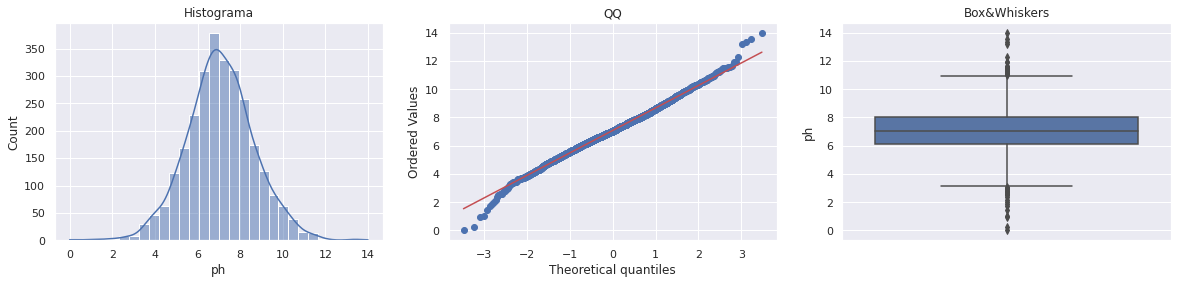

In [ ]:
outlier_diagnostic_plots(water_data, 'ph')

In [ ]:
upper_boundary, lower_boundary = find_normal_boundaries(water_data, 'ph')
upper_boundary, lower_boundary

(11.863753060403255, 2.297835948150383)

##### 1.1- Analisis para potability=0

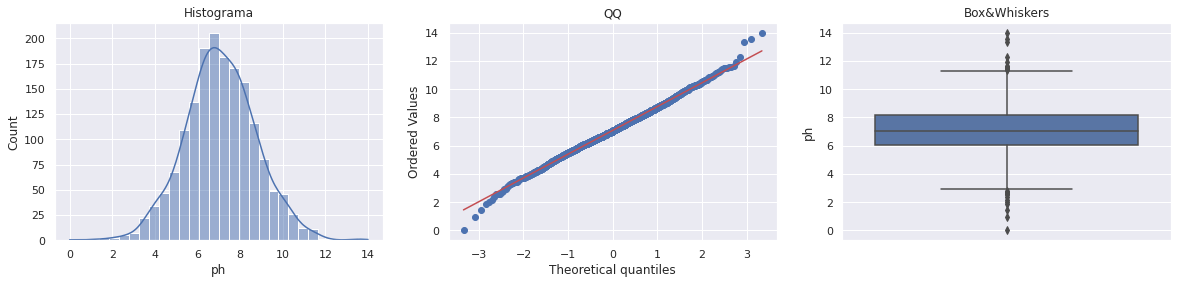

In [ ]:
outlier_diagnostic_plots(water_data[water_data.Potability==0], 'ph')

##### 1.2- Analisis para potability=1

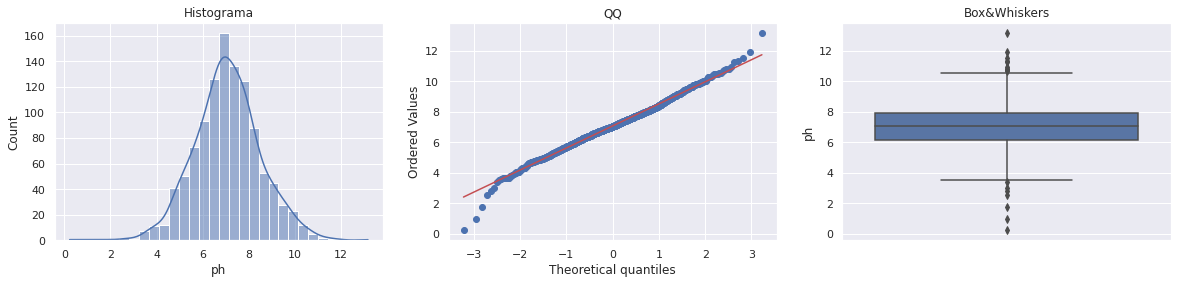

In [ ]:
outlier_diagnostic_plots(water_data[water_data.Potability==1], 'ph')

Las ditribuciones tanto para el caso de potable y no potable son similares.

#### 2- Analisis feature Hardness

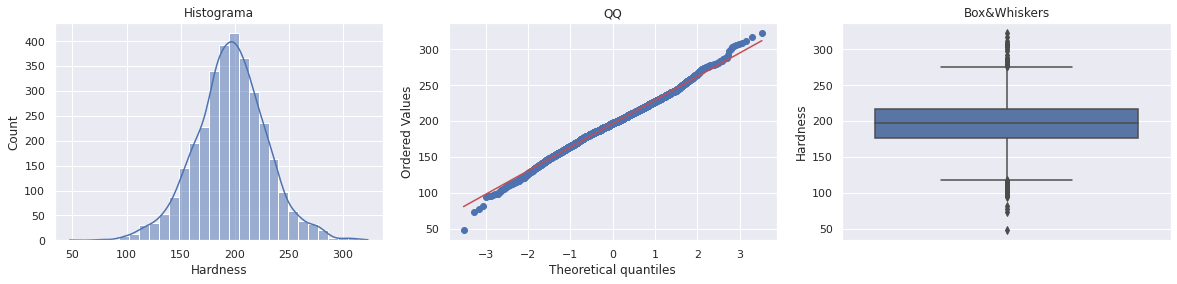

In [ ]:
outlier_diagnostic_plots(water_data, 'Hardness')

In [ ]:
upper_boundary, lower_boundary = find_normal_boundaries(water_data, 'Hardness')
upper_boundary, lower_boundary

(295.00878044618435, 97.73021158841922)

##### 2.1- Analisis para potability=0

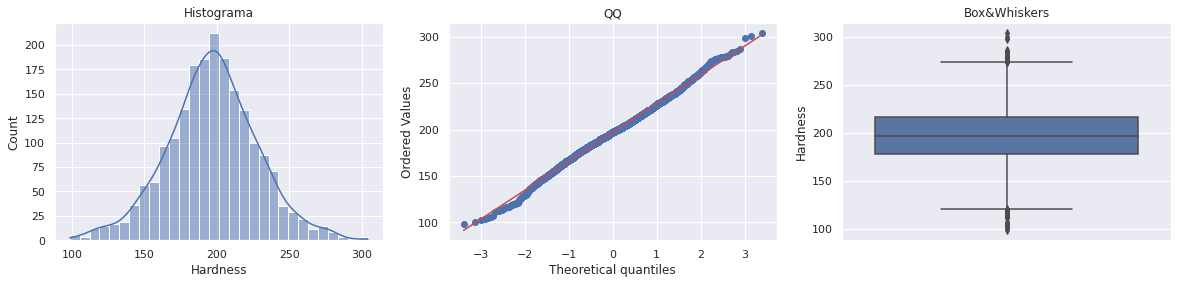

In [ ]:
outlier_diagnostic_plots(water_data[water_data.Potability==0], 'Hardness')

##### 2.2- Analisis para potability=1

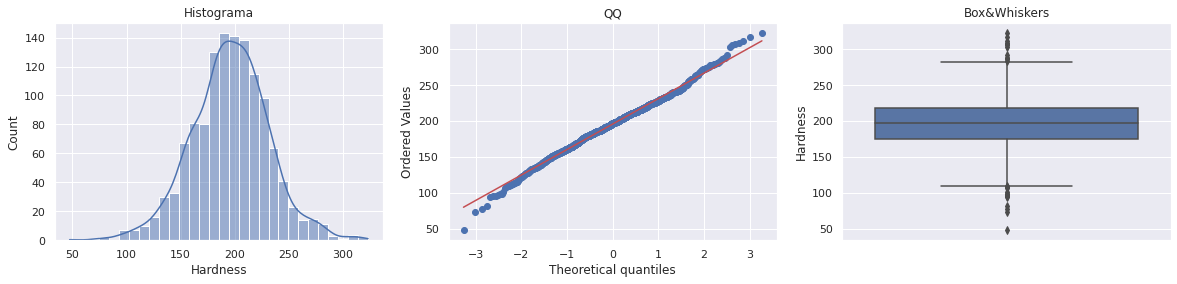

In [ ]:
outlier_diagnostic_plots(water_data[water_data.Potability==1], 'Hardness')

#### 3- Analisis feature Solids

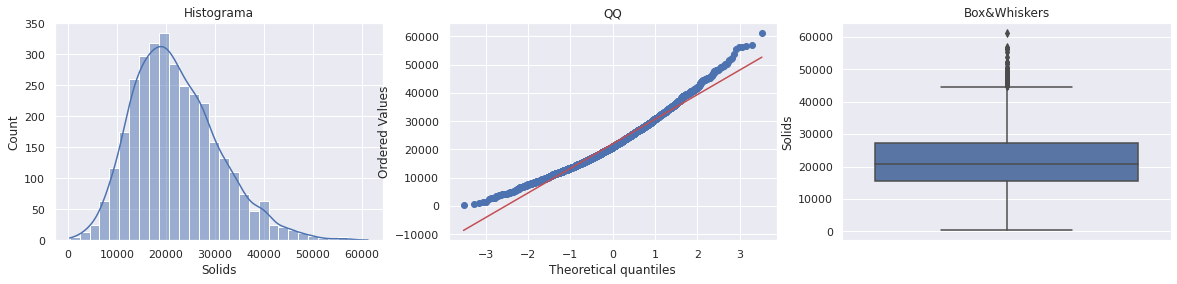

In [ ]:
outlier_diagnostic_plots(water_data, 'Solids')#Llevar a una normal.

In [ ]:
upper_boundary, lower_boundary = find_normal_boundaries(water_data, 'Solids')
upper_boundary, lower_boundary

(48319.80500943491, -4291.619957280687)

##### 3.1- Analisis para potability=0

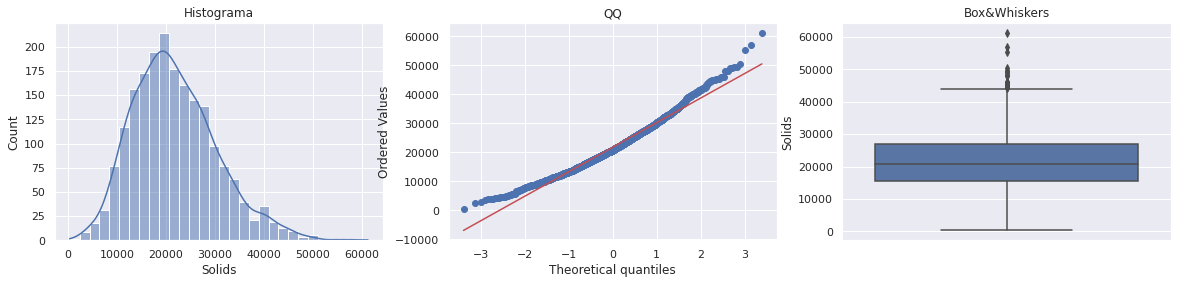

In [ ]:
outlier_diagnostic_plots(water_data[water_data.Potability==0], 'Solids')

##### 3.2- Analisis para potability=1

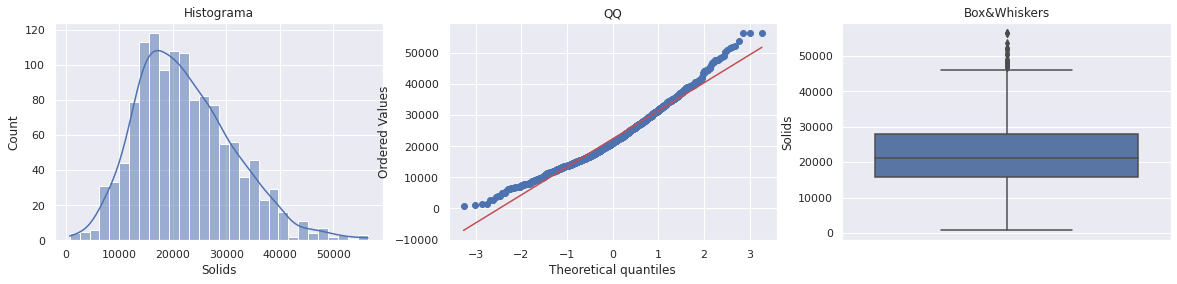

In [ ]:
outlier_diagnostic_plots(water_data[water_data.Potability==1], 'Solids')

#### 4- Analisis feature Chloramines

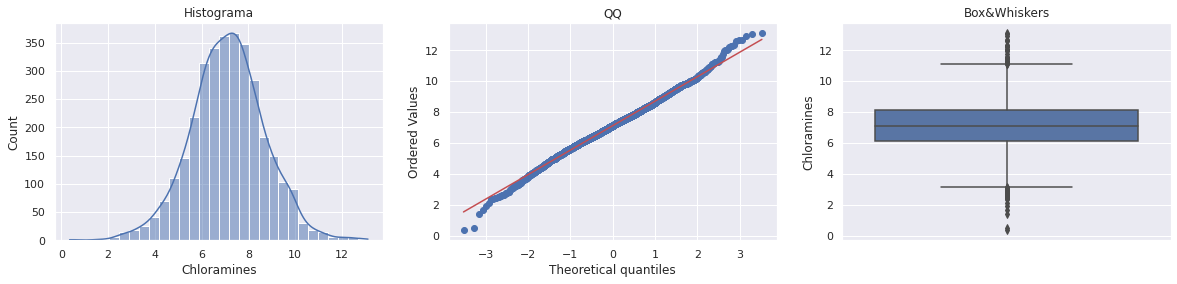

In [ ]:
outlier_diagnostic_plots(water_data, 'Chloramines')

In [ ]:
upper_boundary, lower_boundary = find_normal_boundaries(water_data, 'Chloramines')
upper_boundary, lower_boundary

(11.871531460544917, 2.3730221263066564)

##### 4.1- Analisis para potability=0

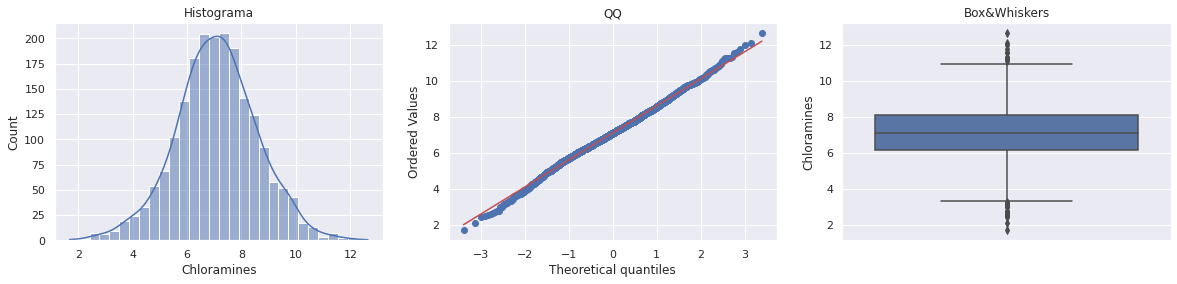

In [ ]:
outlier_diagnostic_plots(water_data[water_data.Potability==0], 'Chloramines')

##### 4.2- Analisis para potability=1

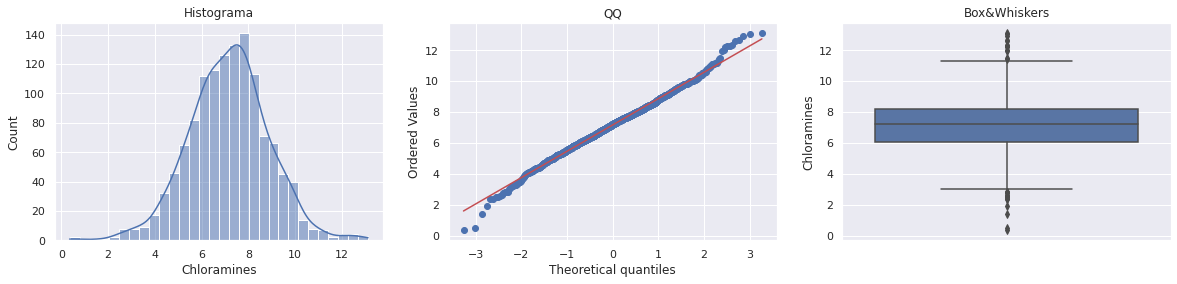

In [ ]:
outlier_diagnostic_plots(water_data[water_data.Potability==1], 'Chloramines')

#### 5- Analisis feature Sulfate

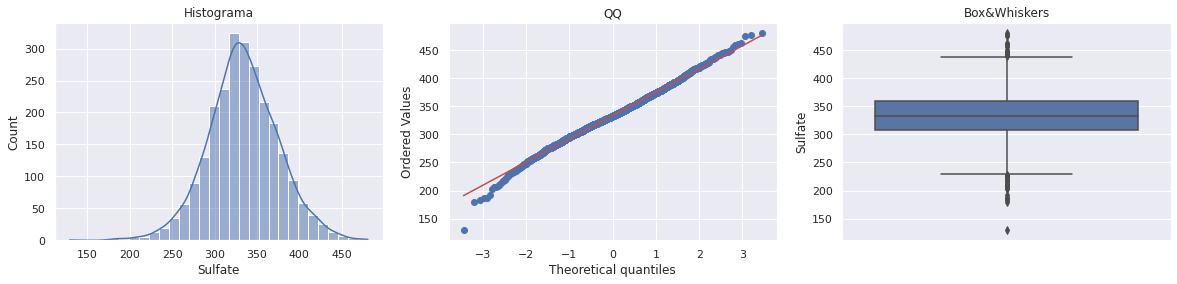

In [ ]:
outlier_diagnostic_plots(water_data, 'Sulfate')

In [ ]:
upper_boundary, lower_boundary = find_normal_boundaries(water_data, 'Sulfate')
upper_boundary, lower_boundary

(458.02629799583144, 209.52525522579535)

##### 5.1- Analisis para potability=0

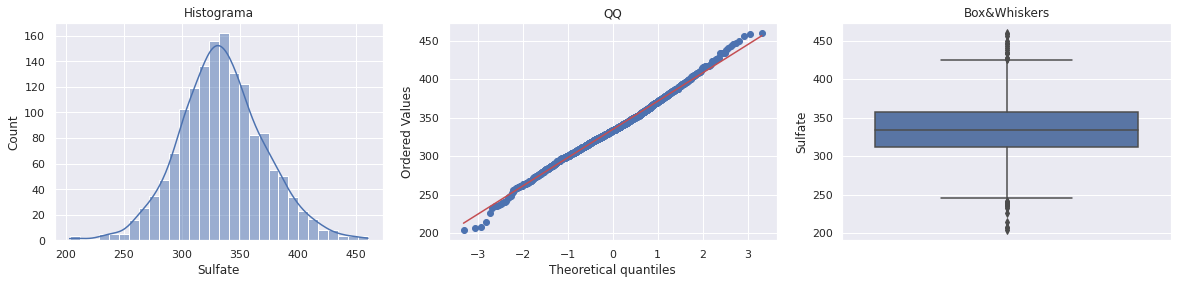

In [ ]:
outlier_diagnostic_plots(water_data[water_data.Potability==0], 'Sulfate')

##### 5.2- Analisis para potability=1

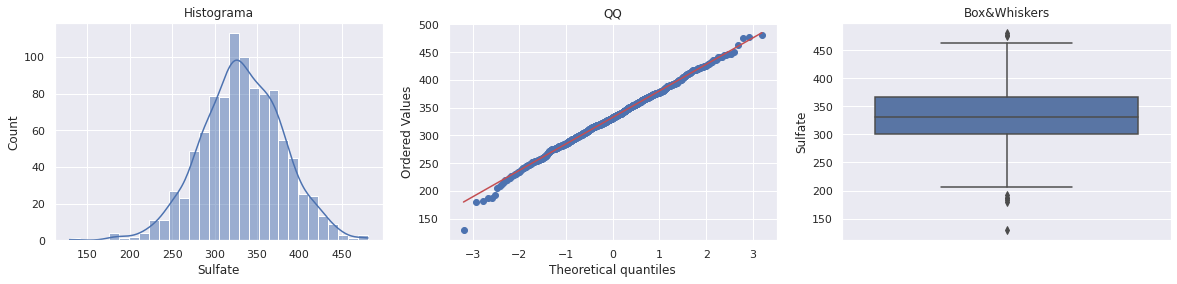

In [ ]:
outlier_diagnostic_plots(water_data[water_data.Potability==1], 'Sulfate')

#### 6- Analisis feature Conductivity

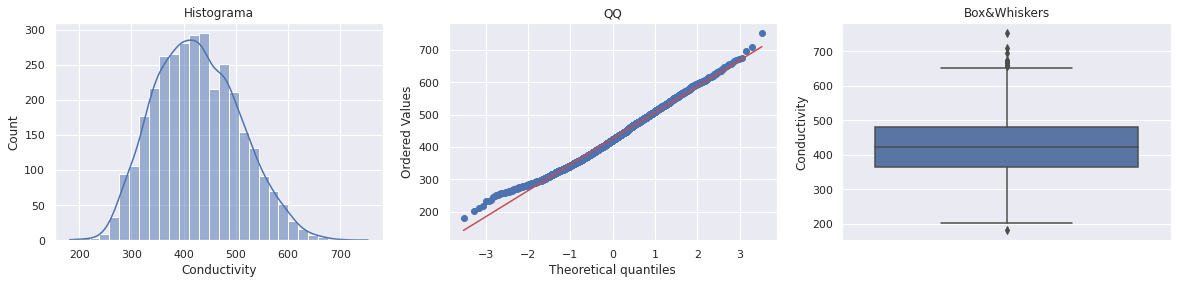

In [ ]:
outlier_diagnostic_plots(water_data, 'Conductivity')#Llevar a una normal.

In [ ]:
upper_boundary, lower_boundary = find_normal_boundaries(water_data, 'Conductivity')
upper_boundary, lower_boundary

(668.6773028358875, 183.73291852921665)

##### 6.1- Analisis para potability=0

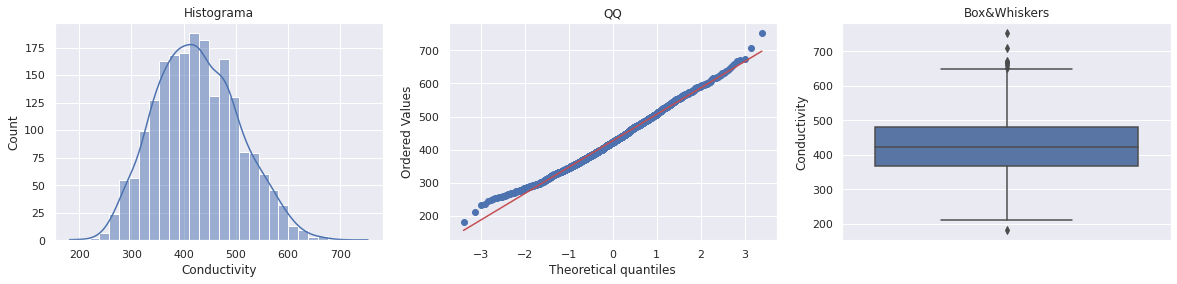

In [ ]:
outlier_diagnostic_plots(water_data[water_data.Potability==0], 'Conductivity')

##### 6.2- Analisis para potability=1

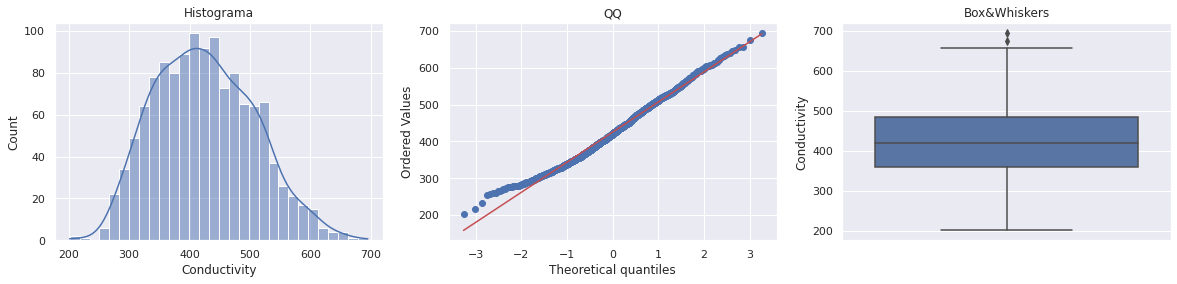

In [ ]:
outlier_diagnostic_plots(water_data[water_data.Potability==1], 'Conductivity')

#### 7- Analisis feature organic_carbon

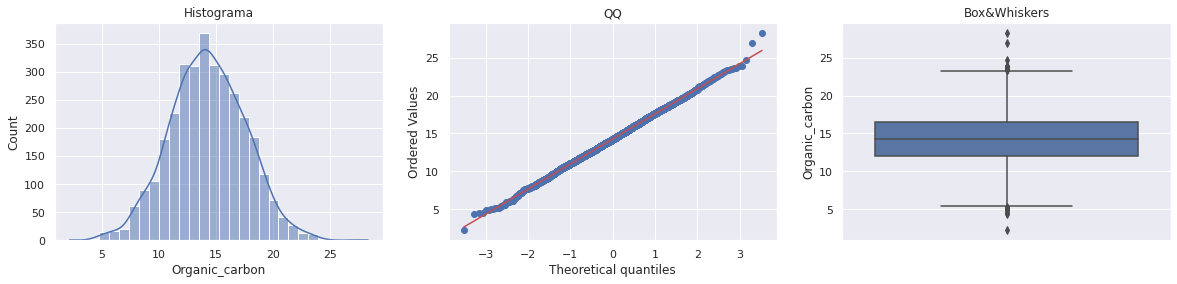

In [ ]:
outlier_diagnostic_plots(water_data, 'Organic_carbon')

In [ ]:
upper_boundary, lower_boundary = find_normal_boundaries(water_data, 'Organic_carbon')
upper_boundary, lower_boundary

(24.20945624505794, 4.360484250296732)

##### 7.1- Analisis para potability=0

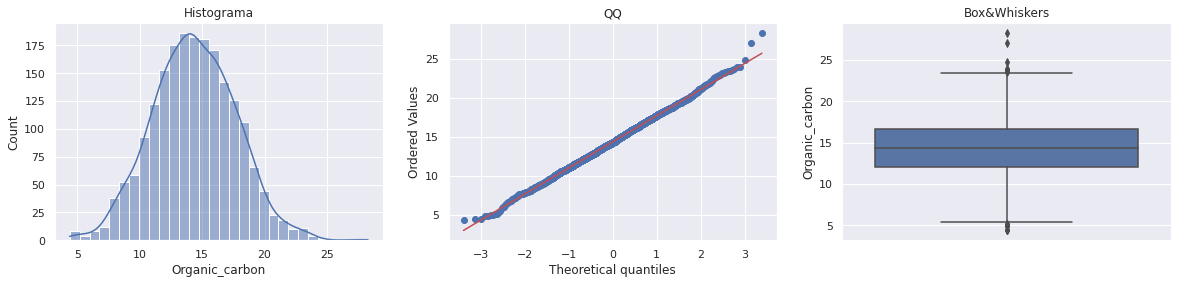

In [ ]:
outlier_diagnostic_plots(water_data[water_data.Potability==0], 'Organic_carbon')

##### 7.2- Analisis para potability=1

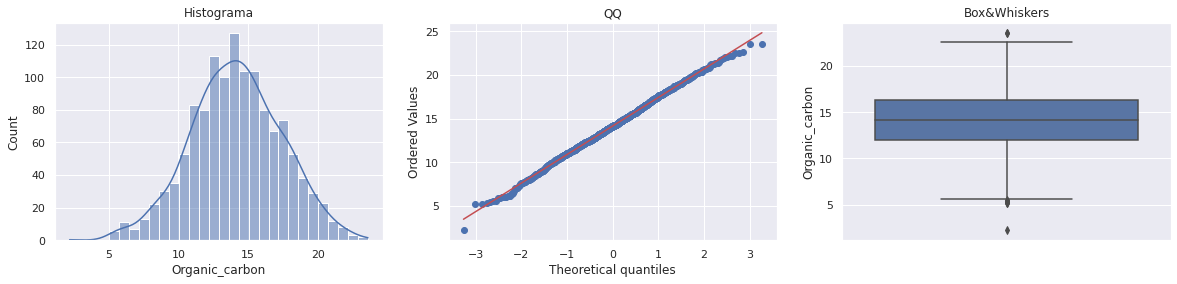

In [ ]:
outlier_diagnostic_plots(water_data[water_data.Potability==1], 'Organic_carbon')

#### 8- Analisis feature Trihalomethanes

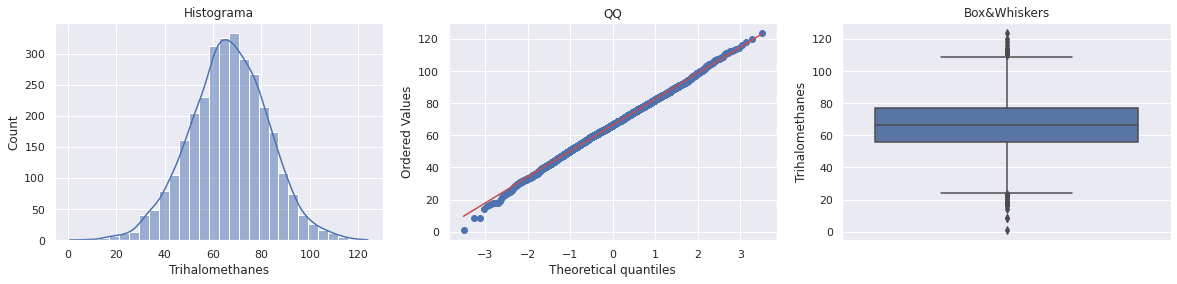

In [ ]:
outlier_diagnostic_plots(water_data, 'Trihalomethanes')

In [ ]:
upper_boundary, lower_boundary = find_normal_boundaries(water_data, 'Trihalomethanes')
upper_boundary, lower_boundary

(114.92131821342397, 17.871267680112084)

##### 8.1- Analisis para potability=0

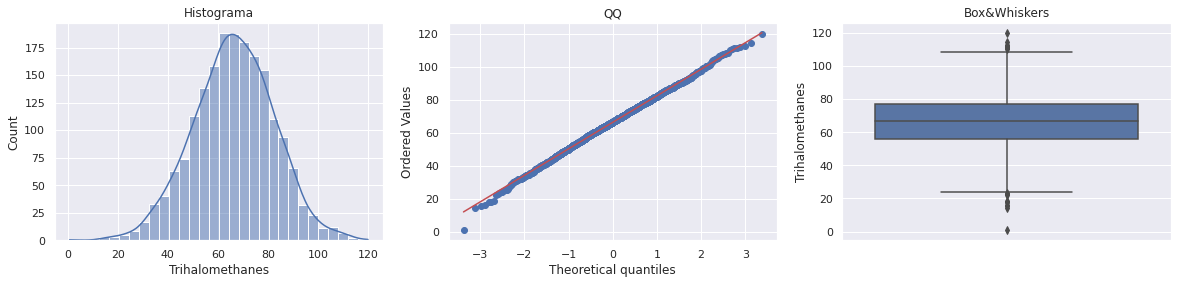

In [ ]:
outlier_diagnostic_plots(water_data[water_data.Potability==0], 'Trihalomethanes')

##### 8.2- Analisis para potability=1

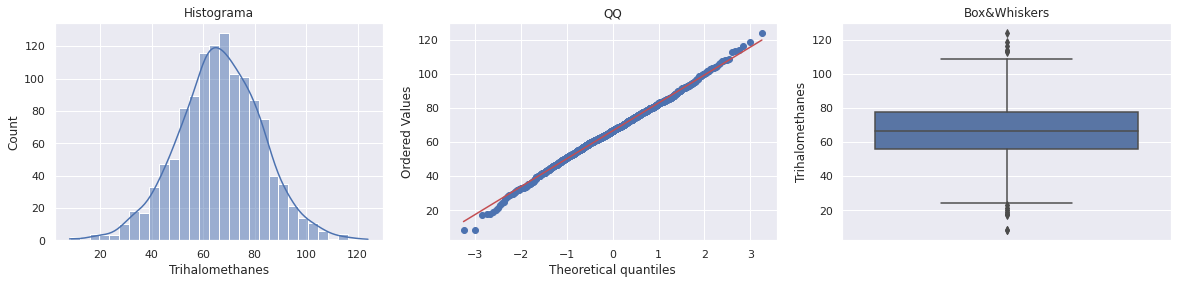

In [ ]:
outlier_diagnostic_plots(water_data[water_data.Potability==1], 'Trihalomethanes')

#### 9- Analisis feature Turbidity

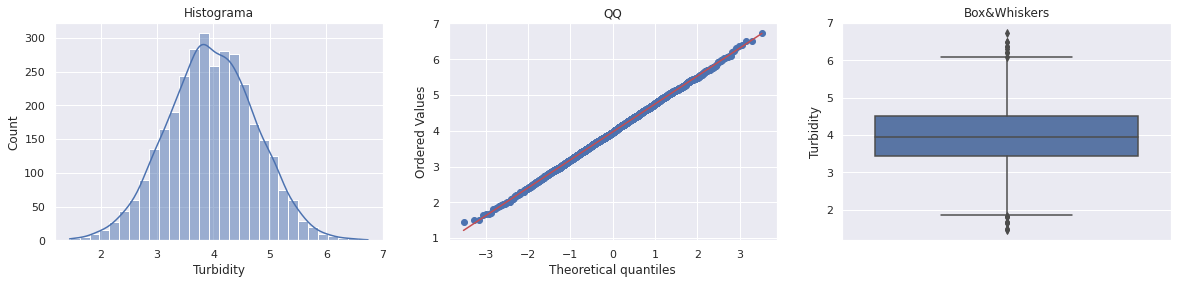

In [ ]:
outlier_diagnostic_plots(water_data, 'Turbidity')

In [ ]:
upper_boundary, lower_boundary = find_normal_boundaries(water_data, 'Turbidity')
upper_boundary, lower_boundary

(6.307933395247293, 1.6256389443348227)

##### 9.1- Analisis para potability=0

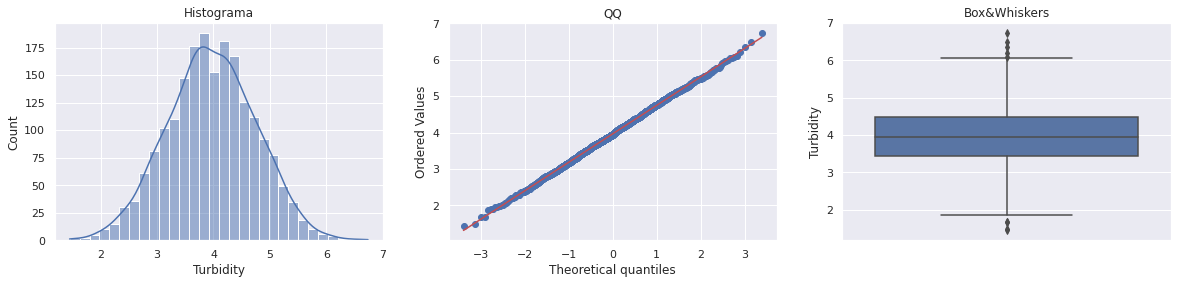

In [ ]:
outlier_diagnostic_plots(water_data[water_data.Potability==0], 'Turbidity')

##### 9.2- Analisis para potability=1

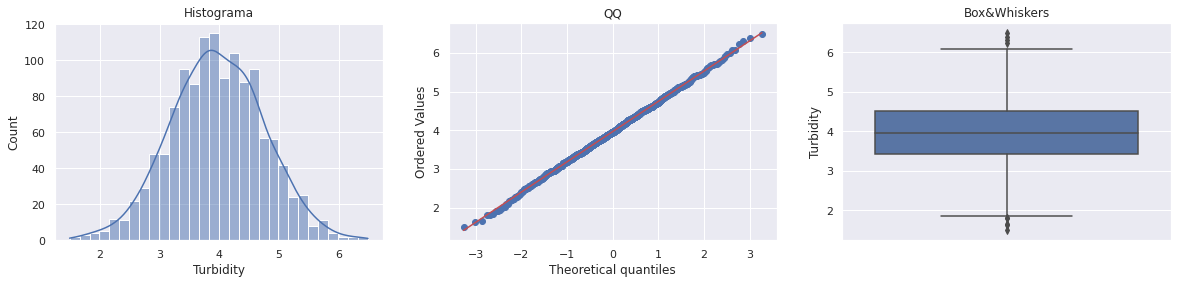

In [ ]:
outlier_diagnostic_plots(water_data[water_data.Potability==1], 'Turbidity')

### Análisis de nuestra variable a precedir (Potability)

#### Análisis de balanceo de clases 

Se observa como las clases están desbalanceadas en un 60% de agua no potable y un 40% de agua potable aproximadamente.

In [ ]:
water_count=water_data['Potability'].value_counts(normalize=True)
water_count

0    0.60989
1    0.39011
Name: Potability, dtype: float64

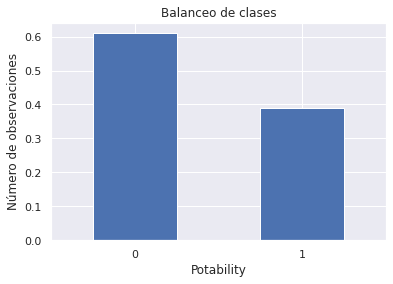

In [ ]:
water_count.plot(kind ='bar', rot=0)
plt.xticks(range(2), np.unique(water_data['Potability']))
plt.title("Balanceo de clases")
plt.xlabel("Potability")
plt.ylabel("Número de observaciones");
plt.show()

#### Distribucion de cada columna contra los valores posibles de potabilidad

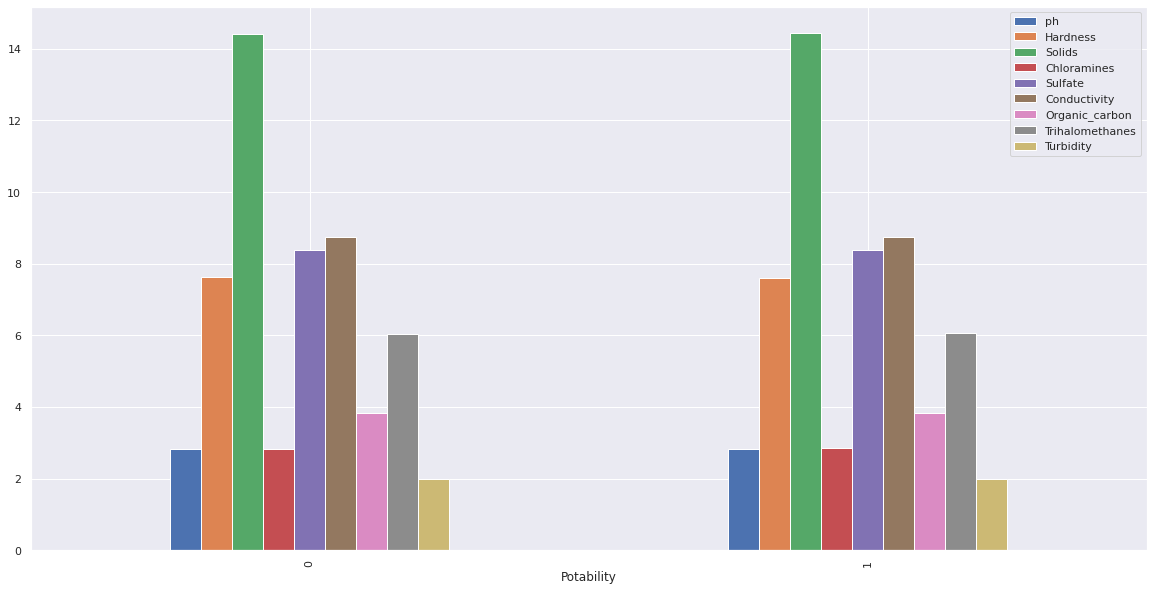

In [ ]:
#Ploteamos en escala logaritmica para ver todos los features juntos
medias_cols_potability = water_data.groupby('Potability').mean()
np.log2(medias_cols_potability).plot(kind="bar",figsize=(20,10))

Gráficamente se ve que las medias de las features son similares para los casos de agua potable y no potable, no se ven diferencias significativas. Esta situación dificulta el aprendizaje del modelo, por la dificultad de detectar diferencias que destaquen una caraterística de otra.

### Análisis de correlacion de los datos

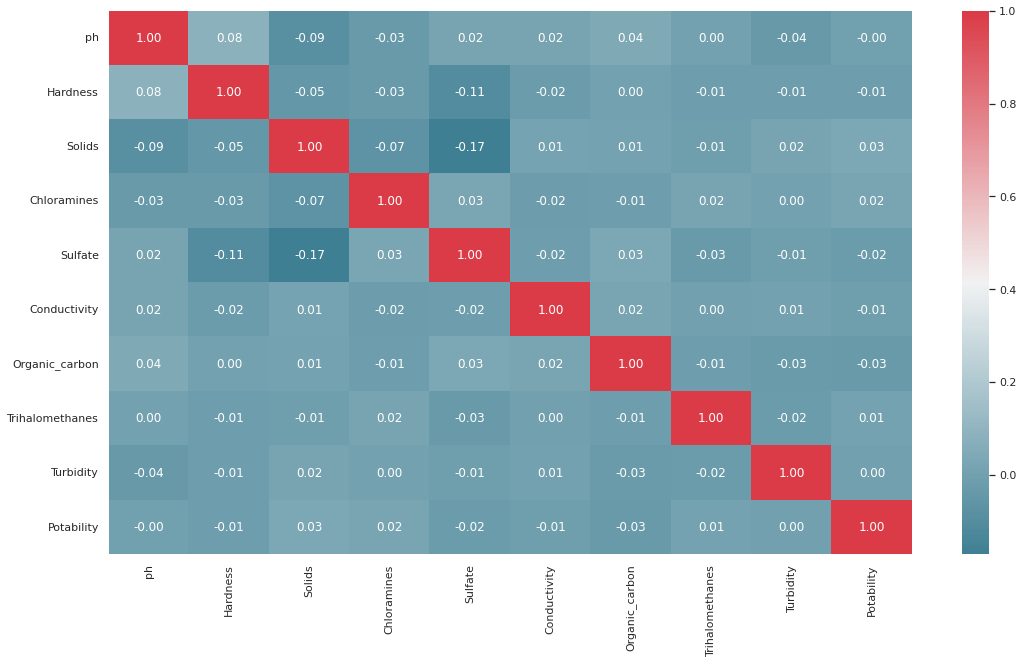

In [ ]:
corr = water_data.corr()
fig, ax1 = plt.subplots(1, figsize=(18, 10))
sns.heatmap(corr, cmap=sns.diverging_palette(220, 10, as_cmap=True), annot=True, fmt=".2f")
sns.set(font_scale=1.5)

No hay características correlacionadas, como se puede observar fuera de la diagonal los valores son cercanos a cero.

In [ ]:
### Pairplot de los datos por potabilidad
sns.pairplot(water_data, hue = 'Potability', diag_kind = 'kde')

Output hidden; open in https://colab.research.google.com to view.

## Preparación de datos

### **Paso 1**: separación del dataset en datos y target

In [ ]:
X, y = water_data.drop(['Potability'], axis=1), water_data.Potability

###**Paso 2**: definición de lista de features numéricas y categóricas

En nuestro caso particular, solo contamos con variables numéricas:

In [ ]:
# Lista de variables numéricas
numeric_features = X.select_dtypes('number').columns.to_list()
numeric_features

['ph',
 'Hardness',
 'Solids',
 'Chloramines',
 'Sulfate',
 'Conductivity',
 'Organic_carbon',
 'Trihalomethanes',
 'Turbidity']

### **Paso 3**: Split en test y train

Se coloca stratify=True para que reparta de manera balanceada las clases entre el set de train y test.

In [ ]:
#Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=rng, stratify=y, shuffle=True)

In [ ]:
X_train.head(10)

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity
2991,6.628256,198.865743,15911.357509,7.517906,342.015924,437.918625,15.005742,38.845958,4.464457
2428,8.848927,262.598329,24417.861325,5.399013,241.126298,493.855489,13.262439,47.112991,5.992325
111,7.875895,226.284788,12710.249452,7.303127,346.403258,445.374147,6.063462,63.128044,4.238589
2293,5.814564,184.541709,29382.335258,6.051233,348.352374,405.621375,18.748201,82.186737,4.131912
2422,7.420641,212.735585,18463.722127,6.727919,355.971495,523.602714,12.086675,44.980102,5.423767
922,5.700785,185.922247,27365.106363,7.563100,NaN,359.506553,15.089441,56.463434,3.978141
948,7.390897,219.335978,25574.091721,8.760434,NaN,553.057663,17.730371,60.598432,4.325132
3133,4.337119,207.361907,34355.618427,6.809153,374.072772,530.069602,12.622032,44.750359,4.401635
3150,6.563357,241.286323,56320.586979,5.365558,NaN,415.817219,11.651929,70.637648,5.292950
1392,4.916741,191.467110,23425.331316,6.857583,NaN,316.422251,18.281754,43.433240,3.613212


In [ ]:
#Se muestran las formas de los set
print (X_train.shape)
print (X_test.shape)
print (y_train.shape)
print (y_test.shape)

(2620, 9)
(656, 9)
(2620,)
(656,)


### **Paso 4**: tranformación para lograr la normalización de los datos de train

Veamos como están los datos de entrenamiento para las dos características antes de la transformación:

In [ ]:
#Observar X_train antes de la transformación
X_train

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity
2991,6.628256,198.865743,15911.357509,7.517906,342.015924,437.918625,15.005742,38.845958,4.464457
2428,8.848927,262.598329,24417.861325,5.399013,241.126298,493.855489,13.262439,47.112991,5.992325
111,7.875895,226.284788,12710.249452,7.303127,346.403258,445.374147,6.063462,63.128044,4.238589
2293,5.814564,184.541709,29382.335258,6.051233,348.352374,405.621375,18.748201,82.186737,4.131912
2422,7.420641,212.735585,18463.722127,6.727919,355.971495,523.602714,12.086675,44.980102,5.423767
...,...,...,...,...,...,...,...,...,...
590,10.059642,175.875828,5232.913254,9.674175,NaN,477.983756,16.470528,62.604551,3.818789
661,NaN,218.573548,11724.623315,7.565407,296.430540,452.727691,14.665704,51.261827,3.561398
2692,4.563371,152.907561,13490.608148,7.499917,338.584921,524.108024,14.143989,69.016240,4.825179
1316,8.969697,195.744765,9049.682595,7.467068,396.453568,378.528511,17.757697,114.208671,3.983099


In [ ]:
X_train_sin_transf = X_train.copy()
X_test_sin_transf = X_test.copy()

Vemos las distribuciones antes de la transformación

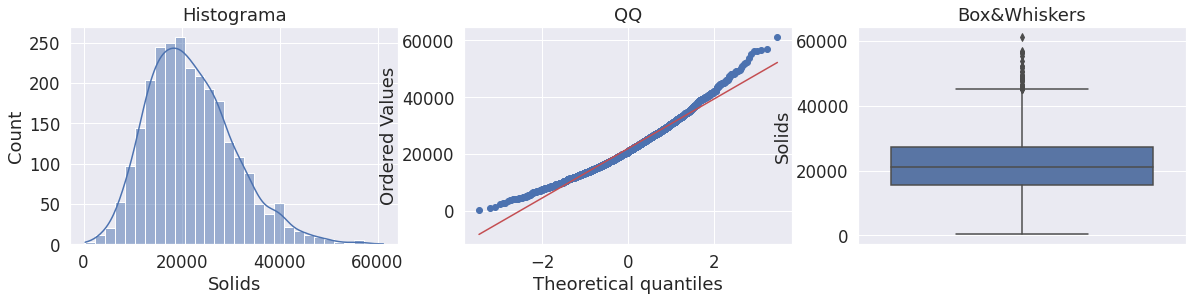

In [ ]:
outlier_diagnostic_plots(X_train, 'Solids')

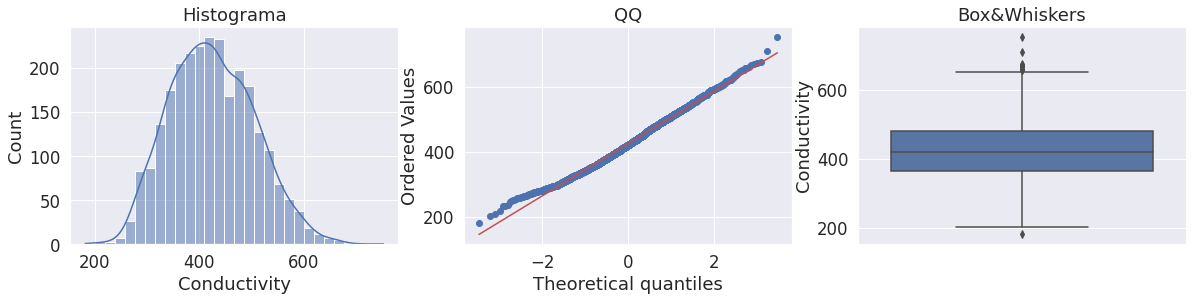

In [ ]:
outlier_diagnostic_plots(X_train, 'Conductivity')

Luego, se comienza con las transformaciones

In [ ]:
#Extraer las dos características a transformar según el análisis anterior
power_data_train = X_train[['Solids','Conductivity']]
power_data_test = X_test[['Solids','Conductivity']]
power_data_train

,Solids,Conductivity
2991,15911.357509,437.918625
2428,24417.861325,493.855489
111,12710.249452,445.374147
2293,29382.335258,405.621375
2422,18463.722127,523.602714
...,...,...
590,5232.913254,477.983756
661,11724.623315,452.727691
2692,13490.608148,524.108024
1316,9049.682595,378.528511


In [ ]:
#Transformar las dos características por el método de yeo-johnson
power_data_pt  = PowerTransformer(method='yeo-johnson',standardize=False,copy=False)

In [ ]:
power_data_train = power_data_pt.fit_transform(power_data_train)
power_data_test = power_data_pt.transform(power_data_test)

Por último, se observan las características transformadas y se reemplazan en el dataset.

In [ ]:
#Se reemplazan en el dataset de train los valores sin transformar de las dos
#características por los valores transformados.

#En train
feature1=power_data_train[:,0].flatten()
X_train=X_train.assign(Solids=feature1)
feature2=power_data_train[:,1].flatten()
X_train=X_train.assign(Conductivity=feature2)

#En test
feature3=power_data_test[:,0].flatten()
X_test=X_test.assign(Solids=feature3)
feature4=power_data_test[:,1].flatten()
X_test=X_test.assign(Conductivity=feature4)

X_train

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity
2991,6.628256,198.865743,256.203765,7.517906,342.015924,32.593399,15.005742,38.845958,4.464457
2428,8.848927,262.598329,318.268478,5.399013,241.126298,34.538368,13.262439,47.112991,5.992325
111,7.875895,226.284788,228.620595,7.303127,346.403258,32.860167,6.063462,63.128044,4.238589
2293,5.814564,184.541709,349.514006,6.051233,348.352374,31.408142,18.748201,82.186737,4.131912
2422,7.420641,212.735585,276.265780,6.727919,355.971495,35.523859,12.086675,44.980102,5.423767
...,...,...,...,...,...,...,...,...,...
590,10.059642,175.875828,145.594253,9.674175,NaN,33.999277,16.470528,62.604551,3.818789
661,NaN,218.573548,219.445733,7.565407,296.430540,33.120911,14.665704,51.261827,3.561398
2692,4.563371,152.907561,235.636465,7.499917,338.584921,35.540332,14.143989,69.016240,4.825179
1316,8.969697,195.744765,192.403750,7.467068,396.453568,30.373539,17.757697,114.208671,3.983099


Y pot último vemos como se han normalizado las features transformadas.

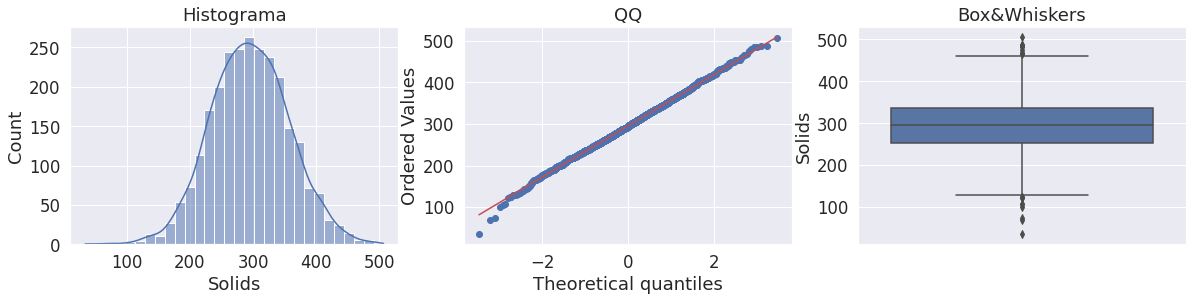

In [ ]:
outlier_diagnostic_plots(X_train, 'Solids')

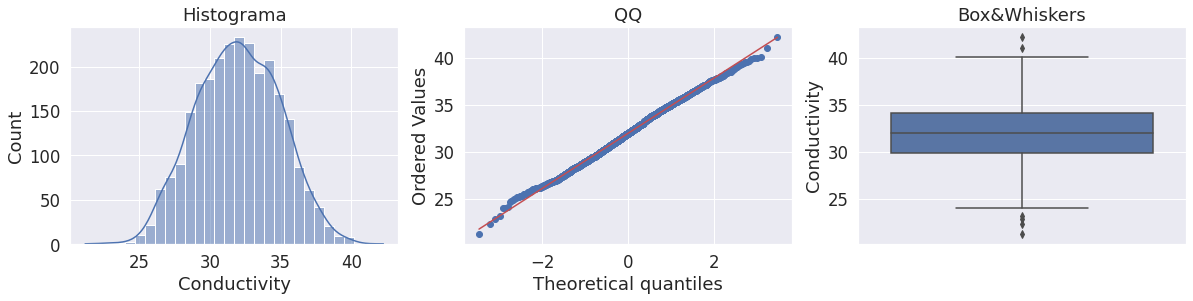

In [ ]:
outlier_diagnostic_plots(X_train, 'Conductivity')

##Preparación del pipeline y entrenamiento de los modelos



Vamos a realizar un pipeline con todas los pasos necesarios para ajustar nuestros datos y procesar los diferentes modelos. Haremos el entrenamiento de los mismo y veremos las métricas resultantes con el dataset de test

### **Paso 1**: transformación de columnas

Se elige el método de KNN para imputar los valores faltantes y StandardScaler para normalizar a media 0 y varianza 1.

In [ ]:
numeric_transformer = Pipeline(steps=[('imputer', KNNImputer()),
                                      ('scaler', StandardScaler())
                                      ])
numeric_transformer

Pipeline(steps=[('imputer', KNNImputer()), ('scaler', StandardScaler())])

In [ ]:
preprocessor = ColumnTransformer(transformers=[('num', numeric_transformer, numeric_features)])
preprocessor

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer', KNNImputer()),
                                                 ('scaler', StandardScaler())]),
                                 ['ph', 'Hardness', 'Solids', 'Chloramines',
                                  'Sulfate', 'Conductivity', 'Organic_carbon',
                                  'Trihalomethanes', 'Turbidity'])])

### **Paso 2**: modelización, elección de hiperparámetros, entrenamiento, test y métricas


#### Modelo baseline

Usamos un modelo random de base para comparar el resto de los modelos que vamos a entrenar.

##### **Paso 2.1**: definimos el modelo

In [ ]:
class RandomModel(object):

    def fit(self, X, y):
        return None

    def predict(self, X):
        return np.random.randint(2, size=X.shape[0])

    def score(self, X,y_true):
        return np.mean(self.predict(X)==y_true)

##### **Paso 2.2**: definimos el pipeline del modelo

In [ ]:
model_randm = Pipeline(steps=[('preprocessor', preprocessor),
                              ('classifier', RandomModel())])

##### **Paso 2.3**: definición de valores de evaluación
Aquí se incluyen:
- Parámetros del método de imputación con sus valores.
- Hiperparámetros del modelo de predicción con sus valores .

In [ ]:
params_randm = {'preprocessor__num__imputer__n_neighbors': [3,5]}
params_randm

{'preprocessor__num__imputer__n_neighbors': [3, 5]}

##### **Paso 2.4**: entrenamiento del modelo

In [ ]:
grid = GridSearchCV(model_randm, params_randm, scoring='precision',cv=KFold(5, random_state=rng, shuffle=True)) 

# fitting del modelo por Randomized Search
grid.fit(X_train, y_train) 
 
# impresión de los mejores hiperparámetros luego del tunning 
print(grid.best_params_) 

{'preprocessor__num__imputer__n_neighbors': 5}


##### **Paso 2.5**: test del modelo

In [ ]:
#predictions_rand_m = random_model.predict(x_test_norm)
grid_predictions_rand = grid.predict(X_test)

##### **Paso 2.6**: evaluación de métricas

In [ ]:
# impresión scoring (en este caso está precision y recall por clase)
print(classification_report(y_test, grid_predictions_rand,zero_division=0)) 

              precision    recall  f1-score   support

           0       0.59      0.48      0.53       400
           1       0.37      0.48      0.42       256

    accuracy                           0.48       656
   macro avg       0.48      0.48      0.48       656
weighted avg       0.51      0.48      0.49       656



In [ ]:
#Precision y recall en general
accuracy_randm=accuracy_score(y_test, grid_predictions_rand)
precision_randm=precision_score(y_test, grid_predictions_rand)
recall_randm=recall_score(y_test, grid_predictions_rand)
print ("Accuracy: ",accuracy_randm)
print ("Precision: ",precision_randm)
print ("Recall: ",recall_randm)

Accuracy:  0.4817073170731707
Precision:  0.3719512195121951
Recall:  0.4765625


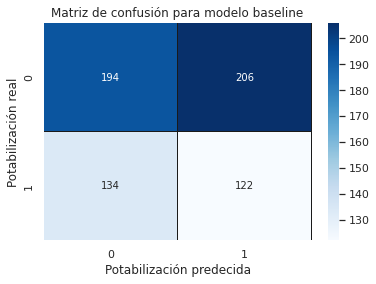

In [ ]:
#Matriz de confusión
sns.heatmap(confusion_matrix(y_test, grid_predictions_rand), annot=True, fmt="d", linewidths=.1, linecolor='k',cmap=plt.cm.Blues)
plt.title('Matriz de confusión para modelo baseline')
plt.ylabel('Potabilización real')
plt.xlabel('Potabilización predecida');

#### Random Forest

##### **Paso 2.1**: preparación del pipeline del modelo

In [ ]:
model_rf = imbpipeline(steps=[('preprocessor', preprocessor),
                           ('balance', RandomOverSampler()),
                           ('classifier', RandomForestClassifier())])
                         

##### **Paso 2.2**: definición de valores de evaluación
Aquí se incluyen:
- Parámetros del método de imputación con sus valores.
- Hiperparámetros del modelo de predicción con sus valores .

In [ ]:
params_rf = {'preprocessor__num__imputer__n_neighbors': [3,5],
              'classifier__n_estimators': [100, 500],
              'classifier__max_depth': [ 6,None], 
              'classifier__max_features': [6, 9], 
              'classifier__min_samples_leaf': [3,9],
              'classifier__random_state': [rng],
              'classifier__criterion': ['gini','entropy']}
params_rf

{'classifier__criterion': ['gini', 'entropy'],
 'classifier__max_depth': [6, None],
 'classifier__max_features': [6, 9],
 'classifier__min_samples_leaf': [3, 9],
 'classifier__n_estimators': [100, 500],
 'classifier__random_state': [22],
 'preprocessor__num__imputer__n_neighbors': [3, 5]}

##### **Paso 2.3**: entrenamiento del modelo
Se utiliza GridSearchCV para:
- Entrenar el modelo con cada combinación de parámetros definidos en 'params'.
- Se aplica cross-validation.

In [ ]:
grid_rf = GridSearchCV(model_rf, params_rf, scoring='precision', cv=KFold(5, random_state=rng, shuffle=True)) 

# fitting del modelo por Randomized Search
grid_rf.fit(X_train, y_train) 
 
# impresión de los mejores hiperparámetros luego del tunning 
print(grid_rf.best_params_) 

{'classifier__criterion': 'entropy', 'classifier__max_depth': None, 'classifier__max_features': 6, 'classifier__min_samples_leaf': 3, 'classifier__n_estimators': 500, 'classifier__random_state': 22, 'preprocessor__num__imputer__n_neighbors': 5}


##### **Paso 2.4**: test del modelo

In [ ]:
grid_predictions_rf = grid_rf.predict(X_test)

##### **Paso 2.5**: evaluación de métricas

In [ ]:
# impresión scoring (en este caso está precision y recall por clase)
print(classification_report(y_test, grid_predictions_rf,zero_division=0)) 

              precision    recall  f1-score   support

           0       0.69      0.80      0.74       400
           1       0.59      0.44      0.50       256

    accuracy                           0.66       656
   macro avg       0.64      0.62      0.62       656
weighted avg       0.65      0.66      0.65       656



In [ ]:
#Precision y recall en general
accuracy_rf=accuracy_score(y_test, grid_predictions_rf)
precision_rf=precision_score(y_test, grid_predictions_rf)
recall_rf=recall_score(y_test, grid_predictions_rf)
print ("Accuracy: ",accuracy_rf)
print ("Precision: ",precision_rf)
print ("Recall: ",recall_rf)

Accuracy:  0.6600609756097561
Precision:  0.5854922279792746
Recall:  0.44140625


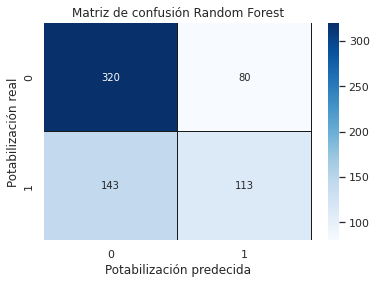

In [ ]:
#Matriz de confusión
sns.heatmap(confusion_matrix(y_test, grid_predictions_rf), annot=True, fmt="d", linewidths=.1, linecolor='k',cmap=plt.cm.Blues)
plt.title('Matriz de confusión Random Forest')
plt.ylabel('Potabilización real')
plt.xlabel('Potabilización predecida');

#### Decision Tree

##### **Paso 2.1**: preparación del pipeline del modelo

In [ ]:
model_dt = imbpipeline(steps=[('preprocessor', preprocessor),
                           ('balance', RandomOverSampler()),
                           ('classifier', DecisionTreeClassifier())])
                           

##### **Paso 2.2**: definición de valores de evaluación
Aquí se incluyen:
- Parámetros del método de imputación con sus valores.
- Hiperparámetros del modelo de predicción con sus valores .

In [ ]:
params_dt = {'preprocessor__num__imputer__n_neighbors': [3, 5],
              'classifier__max_depth': [2, 3, 6], 
              'classifier__max_features': [6, 9], 
              'classifier__min_samples_leaf': [ 3, 5],
              'classifier__criterion': ['gini','entropy'],
              'classifier__random_state': [rng]}
params_dt 

{'classifier__criterion': ['gini', 'entropy'],
 'classifier__max_depth': [2, 3, 6],
 'classifier__max_features': [6, 9],
 'classifier__min_samples_leaf': [3, 5],
 'classifier__random_state': [22],
 'preprocessor__num__imputer__n_neighbors': [3, 5]}

#####**Paso 2.3**: entrenamiento del modelo
Se utiliza GridSearchCV para:
- Entrenar el modelo con cada combinación de parámetros definidos en 'params'.
- Se aplica cross-validation.

In [ ]:
grid_dt = GridSearchCV(model_dt, params_dt, scoring='precision',cv=KFold(5, random_state=rng, shuffle=True)) 

# fitting del modelo por Randomized Search
grid_dt.fit(X_train, y_train) 
 
# impresión de los mejores hiperparámetros luego del tunning 
print(grid_dt.best_params_) 

{'classifier__criterion': 'entropy', 'classifier__max_depth': 3, 'classifier__max_features': 6, 'classifier__min_samples_leaf': 5, 'classifier__random_state': 22, 'preprocessor__num__imputer__n_neighbors': 3}


##### **Paso 2.4**: test del modelo

In [ ]:
grid_predictions_dt = grid_dt.predict(X_test)

##### **Paso 2.5**: evaluación de métricas

In [ ]:
# impresión scoring (en este caso está precision y recall por clase)
print(classification_report(y_test, grid_predictions_dt,zero_division=0)) 

              precision    recall  f1-score   support

           0       0.63      0.92      0.75       400
           1       0.57      0.17      0.26       256

    accuracy                           0.62       656
   macro avg       0.60      0.54      0.50       656
weighted avg       0.61      0.62      0.56       656



In [ ]:
#Precision y recall en general
accuracy_dt=accuracy_score(y_test, grid_predictions_dt)
precision_dt=precision_score(y_test, grid_predictions_dt)
recall_dt=recall_score(y_test, grid_predictions_dt)
print ("Accuracy: ",accuracy_dt)
print ("Precision: ",precision_dt)
print ("Recall: ",recall_dt)

Accuracy:  0.625
Precision:  0.5657894736842105
Recall:  0.16796875


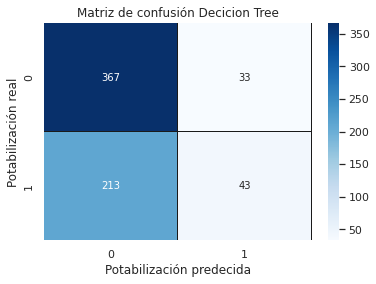

In [ ]:
#Matriz de confusión
sns.heatmap(confusion_matrix(y_test, grid_predictions_dt), annot=True, fmt="d", linewidths=.1, linecolor='k',cmap=plt.cm.Blues)
plt.title('Matriz de confusión Decicion Tree')
plt.ylabel('Potabilización real')
plt.xlabel('Potabilización predecida');

#### SVM

##### **Paso 2.1**: preparación del pipeline del modelo

In [ ]:
model_svm = imbpipeline(steps=[('preprocessor', preprocessor),
                            ('balance', RandomOverSampler()),
                            ('classifier', SVC())])
                           

##### **Paso 2.2**: definición de valores de evaluación
Aquí se incluyen:
- Parámetros del método de imputación con sus valores.
- Hiperparámetros del modelo de predicción con sus valores .

In [ ]:
params_svm = {'preprocessor__num__imputer__n_neighbors': [3,5],
             'classifier__C': [1, 50],  
              'classifier__kernel': ["rbf","linear"], 
              'classifier__class_weight': ['balanced',None], 
              #'classifier__tol': [1e-6,1e-5], 
              #'classifier__max_iter': [10000, 20000], 
              'classifier__gamma': ["scale","auto"],  
              'classifier__random_state': [rng]}

params_svm

{'classifier__C': [1, 50],
 'classifier__class_weight': ['balanced', None],
 'classifier__gamma': ['scale', 'auto'],
 'classifier__kernel': ['rbf', 'linear'],
 'classifier__random_state': [22],
 'preprocessor__num__imputer__n_neighbors': [3, 5]}

#####**Paso 2.3**: entrenamiento del modelo
Se utiliza GridSearchCV para:
- Entrenar el modelo con cada combinación de parámetros definidos en 'params'.
- Se aplica cross-validation.

In [ ]:
grid_svm = GridSearchCV(model_svm, params_svm, scoring='precision', cv=KFold(5, random_state=rng, shuffle=True)) 

# fitting del modelo por Randomized Search
#X_train_sin_transf = X_train.copy()
grid_svm.fit(X_train, y_train) 
 
# impresión de los mejores hiperparámetros luego del tunning 
print(grid_svm.best_params_) 

{'classifier__C': 1, 'classifier__class_weight': None, 'classifier__gamma': 'scale', 'classifier__kernel': 'rbf', 'classifier__random_state': 22, 'preprocessor__num__imputer__n_neighbors': 5}


##### **Paso 2.4**: test del modelo

In [ ]:
grid_predictions_svm = grid_svm.predict(X_test)

##### **Paso 2.5**: evaluación de métricas

In [ ]:
# impresión scoring (en este caso está precision y recall por clase)
print(classification_report(y_test, grid_predictions_svm,zero_division=0)) 

              precision    recall  f1-score   support

           0       0.70      0.69      0.69       400
           1       0.52      0.54      0.53       256

    accuracy                           0.63       656
   macro avg       0.61      0.61      0.61       656
weighted avg       0.63      0.63      0.63       656



In [ ]:
#Precision y recall en general
accuracy_svm=accuracy_score(y_test, grid_predictions_svm)
precision_svm=precision_score(y_test, grid_predictions_svm)
recall_svm=recall_score(y_test, grid_predictions_svm)
print ("Accuracy: ",accuracy_svm)
print ("Precision: ",precision_svm)
print ("Recall: ",recall_svm)

Accuracy:  0.6295731707317073
Precision:  0.524904214559387
Recall:  0.53515625


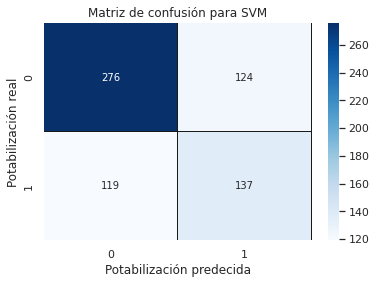

In [ ]:
#Matriz de confusión
sns.heatmap(confusion_matrix(y_test, grid_predictions_svm), annot=True, fmt="d", linewidths=.1, linecolor='k',cmap=plt.cm.Blues)
plt.title('Matriz de confusión para SVM')
plt.ylabel('Potabilización real')
plt.xlabel('Potabilización predecida');

#### Regresión logística

##### **Paso 2.1**: preparación del pipeline del modelo

In [ ]:
model_lr = imbpipeline(steps=[('preprocessor', preprocessor),
                           ('balance', RandomOverSampler()),
                           ('classifier', LogisticRegression())])
                           

##### **Paso 2.2**: definición de valores de evaluación
Aquí se incluyen:
- Parámetros del método de imputación con sus valores.
- Hiperparámetros del modelo de predicción con sus valores .

In [ ]:
params_lr = {'preprocessor__num__imputer__n_neighbors': [3, 5],
              'classifier__penalty': ['l2'], 
              'classifier__class_weight': ['balanced'],  
             'classifier__solver': ['lbfgs','sag','newton-cg'],  
              'classifier__C': [1, 4, 20],
              'classifier__random_state': [rng]}
params_lr

{'classifier__C': [1, 4, 20],
 'classifier__class_weight': ['balanced'],
 'classifier__penalty': ['l2'],
 'classifier__random_state': [RandomState(MT19937) at 0x7FD778D4A270],
 'classifier__solver': ['lbfgs', 'sag', 'newton-cg'],
 'preprocessor__num__imputer__n_neighbors': [3, 5]}

#####**Paso 2.3**: entrenamiento del modelo
Se utiliza GridSearchCV para:
- Entrenar el modelo con cada combinación de parámetros definidos en 'params'.
- Se aplica cross-validation.

In [ ]:
# cross_validation = StratifiedKFold(n_splits=5, shuffle=True, random_state=22)

grid_lr = GridSearchCV(model_lr, params_lr, scoring='precision', cv=KFold(5, random_state=rng, shuffle=True)) 

# fitting del modelo por Randomized Search
grid_lr.fit(X_train, y_train) 
 
# impresión de los mejores hiperparámetros luego del tunning 
print(grid_lr.best_params_) 

{'classifier__C': 4, 'classifier__class_weight': 'balanced', 'classifier__penalty': 'l2', 'classifier__random_state': RandomState(MT19937) at 0x7FD778D4A270, 'classifier__solver': 'sag', 'preprocessor__num__imputer__n_neighbors': 3}


##### **Paso 2.4**: test del modelo

In [ ]:
grid_predictions_lr = grid_lr.predict(X_test)

##### **Paso 2.5**: evaluación de métricas

In [ ]:
# impresión scoring (en este caso está precision y recall por clase)
print(classification_report(y_test, grid_predictions_lr,zero_division=0)) 

              precision    recall  f1-score   support

           0       0.61      0.50      0.55       400
           1       0.39      0.50      0.43       256

    accuracy                           0.50       656
   macro avg       0.50      0.50      0.49       656
weighted avg       0.52      0.50      0.50       656



In [ ]:
#Precision y recall en general
accuracy_lr=accuracy_score(y_test, grid_predictions_lr)
precision_lr=precision_score(y_test, grid_predictions_lr)
recall_lr=recall_score(y_test, grid_predictions_lr)
print ("Accuracy: ",accuracy_lr)
print ("Precision: ",precision_lr)
print ("Recall: ",recall_lr)

Accuracy:  0.4969512195121951
Precision:  0.3871951219512195
Recall:  0.49609375


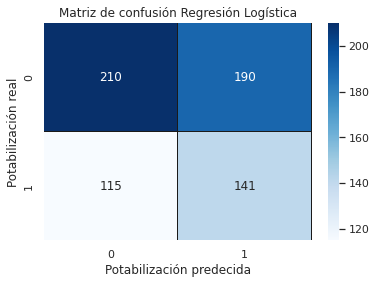

In [ ]:
#Matriz de confusión
sns.heatmap(confusion_matrix(y_test, grid_predictions_lr), annot=True, fmt="d", linewidths=.1, linecolor='k',cmap=plt.cm.Blues)
plt.title('Matriz de confusión Regresión Logística')
plt.ylabel('Potabilización real')
plt.xlabel('Potabilización predecida');

#### K-Means

##### **Paso 2.1**: preparación del pipeline del modelo

In [ ]:
model_km = Pipeline(steps=[('preprocessor', preprocessor),
                           ('classifier', KMeans())])
                           

##### **Paso 2.2**: definición de valores de evaluación
Aquí se incluyen:
- Parámetros del método de imputación con sus valores.
- Hiperparámetros del modelo de predicción con sus valores .

In [ ]:
params_km = {'preprocessor__num__imputer__n_neighbors': [3,5],
             'classifier__n_clusters': [2],  
              'classifier__init': ['k-means++', 'random'],  
              'classifier__random_state': [rng]}

params_km

{'classifier__init': ['k-means++', 'random'],
 'classifier__n_clusters': [2],
 'classifier__random_state': [22],
 'preprocessor__num__imputer__n_neighbors': [3, 5]}

#####**Paso 2.3**: entrenamiento del modelo
Se utiliza GridSearchCV para:
- Entrenar el modelo con cada combinación de parámetros definidos en 'params'.
- Se aplica cross-validation.

In [ ]:
grid_km = GridSearchCV(model_km, params_km, scoring='precision', cv=KFold(5, random_state=rng, shuffle=True)) 

# fitting del modelo por Randomized Search
grid_km.fit(X_train, y_train) 
 
# impresión de los mejores hiperparámetros luego del tunning 
print(grid_km.best_params_) 

{'classifier__init': 'random', 'classifier__n_clusters': 2, 'classifier__random_state': 22, 'preprocessor__num__imputer__n_neighbors': 3}


##### **Paso 2.4**: test del modelo

In [ ]:
grid_predictions_km = grid_km.predict(X_test)

##### **Paso 2.5**: evaluación de métricas

In [ ]:
# impresión scoring (en este caso está precision y recall por clase)
print(classification_report(y_test, grid_predictions_km,zero_division=0)) 

              precision    recall  f1-score   support

           0       0.59      0.47      0.53       400
           1       0.37      0.49      0.42       256

    accuracy                           0.48       656
   macro avg       0.48      0.48      0.48       656
weighted avg       0.51      0.48      0.49       656



In [ ]:
#Precision y recall en general
accuracy_km=accuracy_score(y_test, grid_predictions_km)
precision_km=precision_score(y_test, grid_predictions_km)
recall_km=recall_score(y_test, grid_predictions_km)
print ("Accuracy: ",accuracy_km)
print ("Precision: ",precision_km)
print ("Recall: ",recall_km)

Accuracy:  0.4801829268292683
Precision:  0.37388724035608306
Recall:  0.4921875


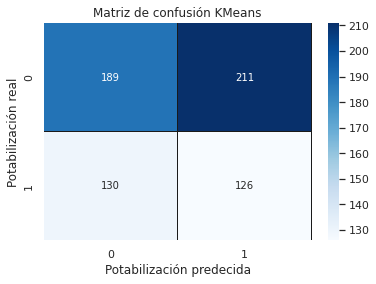

In [ ]:
#Matriz de confusión
sns.heatmap(confusion_matrix(y_test, grid_predictions_km), annot=True, fmt="d", linewidths=.1, linecolor='k',cmap=plt.cm.Blues)
plt.title('Matriz de confusión KMeans')
plt.ylabel('Potabilización real')
plt.xlabel('Potabilización predecida');

## Visualización de agrupamiento y distribución de datos
Ahora se pretende observar cómo se agrupan y distribuyen los datos en agrupamientos. Esta operación no implica que se pueda conocer directamente a qué variables pertenecen los datos. Se parte del dataset X, previo al análisis de todos los modelos. 
Los pasos para obtener los gráficos son:
1. Imputación de los valores nulos por el método de [vecinos cercanos](https://scikit-learn.org/stable/modules/generated/sklearn.impute.KNNImputer.html).

1. [Estandarización](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html?highlight=standardscaler#sklearn.preprocessing.StandardScaler) del dataset.

1. Aplicación de [KMeans](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html?highlight=kmeans#sklearn.cluster.KMeans), segmentando el dataset en dos cluster. 

1. Con la segmentación de los datos, se aplica [T-SNE](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html?highlight=t%20sne#sklearn.manifold.TSNE) para graficar.



In [ ]:
# Imputación por KNN
knn = KNNImputer(n_neighbors=5) 
X_imputer = knn.fit_transform(X)


In [ ]:
# Escalado
scaler = StandardScaler()
X_transform = scaler.fit_transform(X_imputer)

In [ ]:
# Segmentación por KMeans
kmeans = KMeans(n_clusters=2, random_state=25)
kmeans.fit(X_transform)

# Array con la distribución de los datos por cluster
cluster = kmeans.labels_
print("Distribución de datos por cluster: ", np.bincount(cluster)/len(cluster))


Distribución de datos por cluster:  [0.45573871 0.54426129]


Aplicación de la técnica T-SNE. Se realiza sobre tres componentes principales para graficar en 3D. 

In [ ]:
# T-SNE
X_tsne_3D = TSNE(n_components=3, 
                 learning_rate="auto", 
                 perplexity=30, 
                 init="pca", 
                 random_state=rng).fit_transform(X_transform)

/usr/local/lib/python3.7/dist-packages/sklearn/manifold/_t_sne.py:986: FutureWarning: The PCA initialization in TSNE will change to have the standard deviation of PC1 equal to 1e-4 in 1.2. This will ensure better convergence.
  FutureWarning,


Generación del gráfico 3D

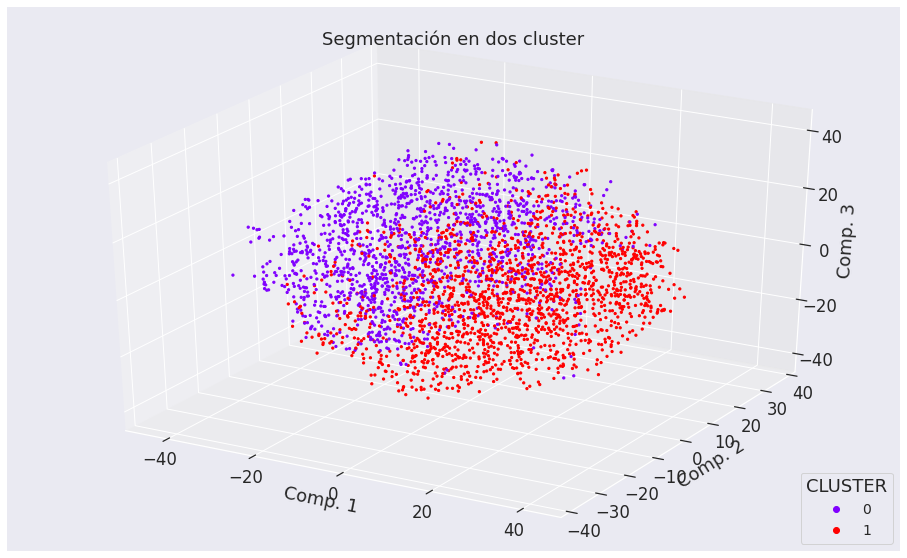

In [ ]:
ax = plt.figure(figsize=(16,10)).gca(projection='3d')

p = ax.scatter(xs = X_tsne_3D[:, 0], 
                 ys = X_tsne_3D[:, 1], 
                 zs = X_tsne_3D[:, 2],
                 c = cluster, alpha=1, s=5, cmap = plt.cm.get_cmap("rainbow",2))

plt.legend(*p.legend_elements(), 
           title="CLUSTER",
           loc=4, fontsize='14', fancybox=True)
plt.title('Segmentación en dos cluster')
ax.set_xlabel('Comp. 1')
ax.set_ylabel('Comp. 2')
ax.set_zlabel('Comp. 3')
plt.show()

Por los resultados del gráfico, los agrupamientos de datos no han logrado separarse. Se busca en 2D una posible frontera.

In [ ]:
X_tsne_2D = TSNE(n_components=2, 
                                  learning_rate="auto", 
                                  perplexity=40, 
                                  init="pca", 
                                  random_state=rng).fit_transform(X_transform)

/usr/local/lib/python3.7/dist-packages/sklearn/manifold/_t_sne.py:986: FutureWarning: The PCA initialization in TSNE will change to have the standard deviation of PC1 equal to 1e-4 in 1.2. This will ensure better convergence.
  FutureWarning,


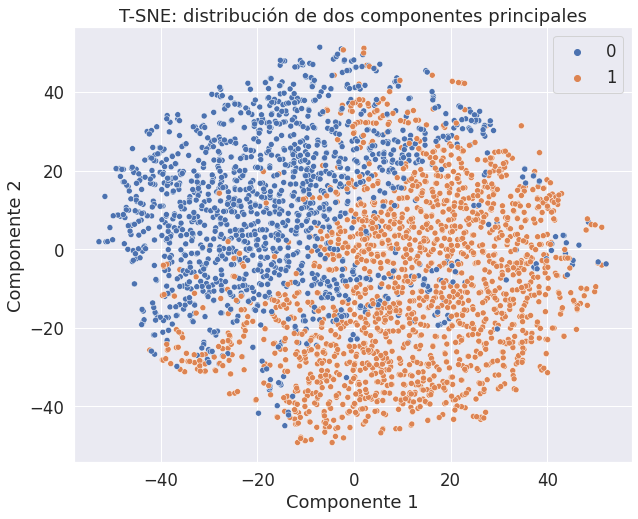

In [ ]:
# Gráfico 2D
plt.figure(figsize=(10,8))
sns.scatterplot(x = X_tsne_2D[:, 0], y = X_tsne_2D[:, 1], hue = cluster, legend='full')
plt.title('T-SNE: distribución de dos componentes principales')
plt.xlabel('Componente 1')
plt.ylabel('Componente 2')
plt.show()

Los datos separados en dos cluster, no logran separarse, se entremezclan. Situación que afecta la performance de los modelos de clasificación. 

## **Conclusiones**

### Resultados

A continuación se presenta un cuadro y un gráfico comparativo de métricas entre todos los modelos que se han utilizado.

In [ ]:
metrics_show = [ ["0: Baseline", accuracy_randm, precision_randm, recall_randm],
                 ["1: Random Forest", accuracy_rf, precision_rf, recall_rf],
                 ["2: Decision Tree", accuracy_dt, precision_dt, recall_dt],
                 ["3: Support Vector Classification", accuracy_svm, precision_svm, recall_svm],
                 ["4: Logistic Regression", accuracy_lr, precision_lr, recall_lr],
                 ["5: Kmeans", accuracy_km, precision_km, recall_km]]

dataframe_conclusion = pd.DataFrame(metrics_show, columns = ['Nombre','Accuracy','Precision','Recall'])
print(dataframe_conclusion)

                             Nombre  Accuracy  Precision    Recall
0                       0: Baseline  0.481707   0.371951  0.476562
1                  1: Random Forest  0.660061   0.585492  0.441406
2                  2: Decision Tree  0.625000   0.565789  0.167969
3  3: Support Vector Classification  0.629573   0.524904  0.535156
4            4: Logistic Regression  0.535061   0.425982  0.550781
5                         5: Kmeans  0.480183   0.373887  0.492188


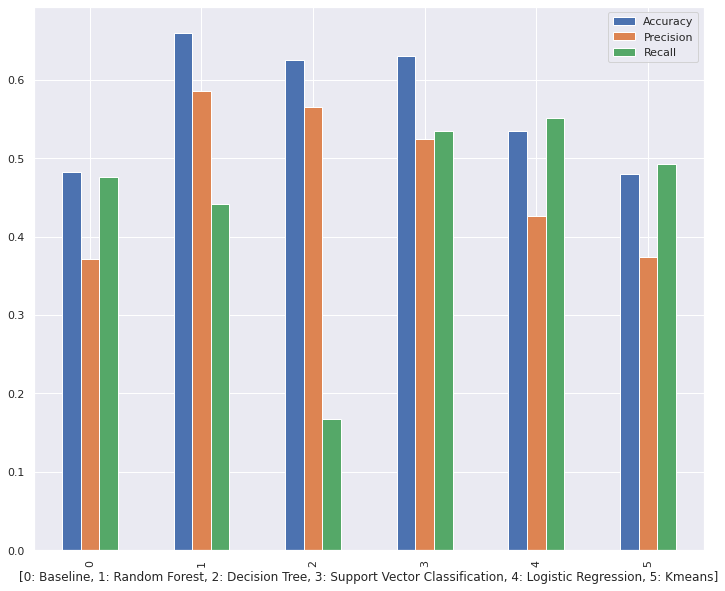

In [ ]:
dataframe_conclusion.plot(kind="bar",figsize=(12,10),xlabel=dataframe_conclusion['Nombre'])

#### Comparativa con modelos corridos sin foco en la precision (GridSearchCV sin scoring='precision')

In [ ]:
metrics_show = [ ["0: Baseline",  0.496951, 0.388554, 0.503906],
                 ["1: Random Forest", 0.654634, 0.580000, 0.460938],
                 ["2: Decision Tree", 0.602134,  0.490421, 0.500000],
                 ["3: Support Vector Classification", 0.625671, 0.515865, 0.496094],
                 ["4: Logistic Regression", 0.519817, 0.411411, 0.535156],
                 ["5: Kmeans", 0.480183, 0.373887, 0.492188]]

df_conclusion_sin_scoring = pd.DataFrame(metrics_show, columns = ['Nombre','Accuracy','Precision','Recall'])
print(df_conclusion_sin_scoring)

                             Nombre  Accuracy  Precision    Recall
0                       0: Baseline  0.496951   0.388554  0.503906
1                  1: Random Forest  0.654634   0.580000  0.460938
2                  2: Decision Tree  0.602134   0.490421  0.500000
3  3: Support Vector Classification  0.625671   0.515865  0.496094
4            4: Logistic Regression  0.519817   0.411411  0.535156
5                         5: Kmeans  0.480183   0.373887  0.492188


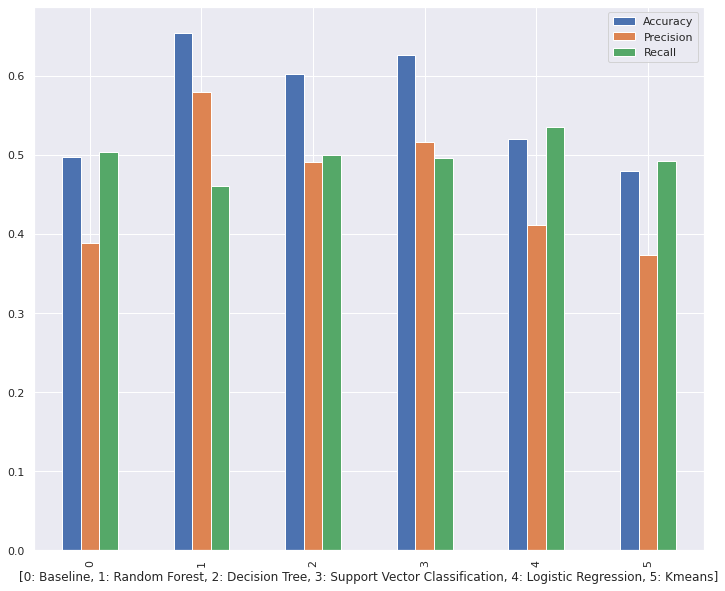

In [ ]:
df_conclusion_sin_scoring.plot(kind="bar",figsize=(12,10),xlabel=df_conclusion_sin_scoring['Nombre'])

#### Comparativa con modelos sin transformacion de distribuciones

Se probaron los modelos utilizando el dataset original sin tratamiento, para ver los resultados obtenidos

##### con GridSearchCV con scoring

In [ ]:
metrics_show = [ ["0: Baseline",  0.498476, 0.384127, 0.472656],
                 ["1: Random Forest", 0.646341,  0.561856,  0.425781],
                 ["2: Decision Tree", 0.609756, 0.500000, 0.324219],
                 ["3: Support Vector Classification", 0.608232, 0.497992, 0.484375],
                 ["4: Logistic Regression", 0.527439, 0.418675, 0.542969],
                 ["5: Kmeans", 0.530488, 0.415584, 0.5]]

df_conclu_sin_transf_c_score = pd.DataFrame(metrics_show, columns = ['Nombre','Accuracy','Precision','Recall'])
print(df_conclu_sin_transf_c_score)

                             Nombre  Accuracy  Precision    Recall
0                       0: Baseline  0.498476   0.384127  0.472656
1                  1: Random Forest  0.646341   0.561856  0.425781
2                  2: Decision Tree  0.609756   0.500000  0.324219
3  3: Support Vector Classification  0.608232   0.497992  0.484375
4            4: Logistic Regression  0.527439   0.418675  0.542969
5                         5: Kmeans  0.530488   0.415584  0.500000


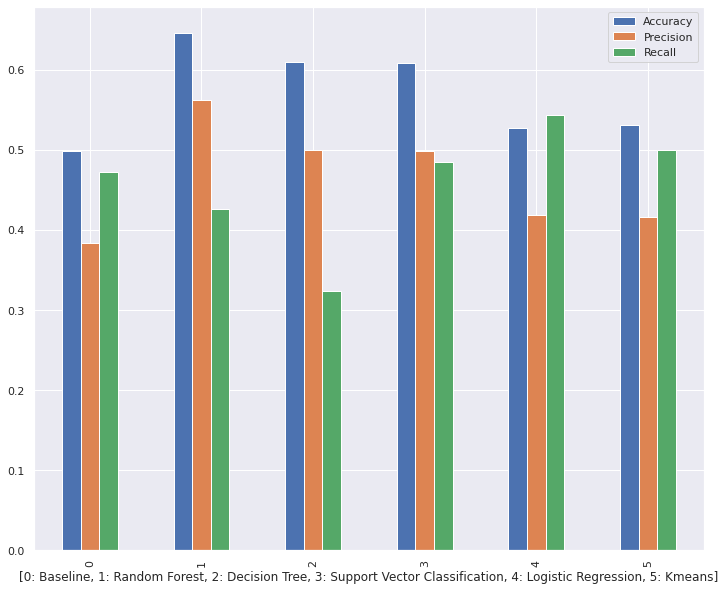

In [ ]:
df_conclu_sin_transf_c_score.plot(kind="bar",figsize=(12,10),xlabel=df_conclu_sin_transf_c_score['Nombre'])

##### con GridSearchCV sin scoring

In [ ]:
metrics_show = [ ["0: Baseline",  0.495427, 0.390029, 0.519531],
                 ["1: Random Forest", 0.661585, 0.584158, 0.460938],
                 ["2: Decision Tree", 0.628049, 0.583333, 0.164062],
                 ["3: Support Vector Classification", 0.606707, 0.495868, 0.468750],
                 ["4: Logistic Regression", 0.516768, 0.406728, 0.519531],
                 ["5: Kmeans", 0.524390, 0.407895, 0.484375]]

df_conclu_sin_transf_s_score = pd.DataFrame(metrics_show, columns = ['Nombre','Accuracy','Precision','Recall'])
print(df_conclu_sin_transf_s_score)

                             Nombre  Accuracy  Precision    Recall
0                       0: Baseline  0.495427   0.390029  0.519531
1                  1: Random Forest  0.661585   0.584158  0.460938
2                  2: Decision Tree  0.628049   0.583333  0.164062
3  3: Support Vector Classification  0.606707   0.495868  0.468750
4            4: Logistic Regression  0.516768   0.406728  0.519531
5                         5: Kmeans  0.524390   0.407895  0.484375


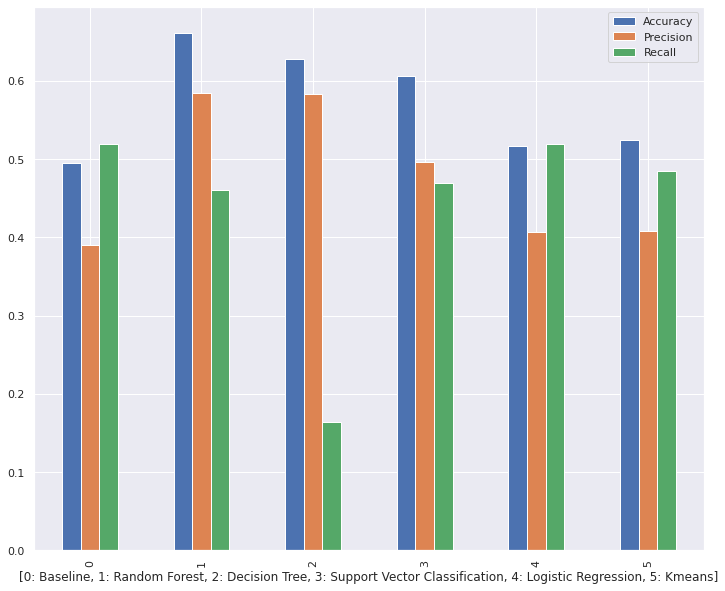

In [ ]:
df_conclu_sin_transf_s_score.plot(kind="bar",figsize=(12,10),xlabel=df_conclu_sin_transf_s_score['Nombre'])

#### Comparativa final entre los diferentes tratamientos (solo precision)

In [ ]:
dataframe_comparativa = pd.DataFrame(dataframe_conclusion.Precision).rename(columns = {'Precision':'Transf_y_scoring'})
dataframe_comparativa["Transf_sin_scoring"] = pd.DataFrame(df_conclusion_sin_scoring.Precision)
dataframe_comparativa["Original_y_scoring"] = pd.DataFrame(df_conclu_sin_transf_c_score.Precision)
dataframe_comparativa["Original_sin_scoring"] = pd.DataFrame(df_conclu_sin_transf_c_score.Precision)

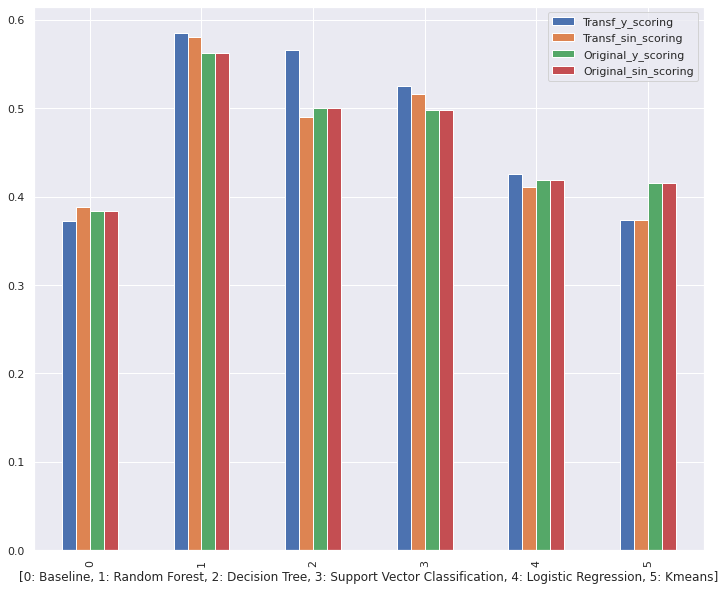

In [ ]:
dataframe_comparativa.plot(kind="bar",figsize=(12,10),xlabel=dataframe_conclusion['Nombre'])

### Modelo ganador: Random Forest

En primer lugar, es importante explicar la importancia de la métrica precision en este problema, ya que debemos evitar que se indique que algo es agua potable cuando en realidad no lo es. Caso contrario, podría traer serios problemas a los humanos que consuman dicha agua y pérdidas económicas inmensurables. Incluso, en este problema, la precision es más importante que el recall, ya que si no es buena la detección de agua potable, es decir, se pierde la posibilidad de detectar agua potable, esto solo traerá pérdidas en términos de oportunidades de negocio, pero no trerá daños legales a la empresa.

Teniendo en cuenta eso, según se puede apreciar, el modelo ganador es el RANDOM FOREST, ya que cuenta con las mejores métricas de accuracy y precision. También, de los resultados se observa que es conveniente aplicar la transformación de las características que no tienen forma normal (sólidos y conductividad) y que es importante buscar los mejores hiperparámetros, ya que esto mejora la métrica de precision.

### Limitaciones que generan problemas de clasificación

Más allá de todo el trabajo realizado, se observa que las métricas del modelo ganador no alcanzan el 70%.
Detectamos que con las muestras presentes nos encontramos con dos problemas importantes:


*   La distribución de las características es muy similar, ya sea que se trate o no de agua potable.
*   Si se encarara como un problema de segmentación de 2 clusters, se ve claramente que no hay una buena separación entre ambos, lo que nos da indicio que es difícil clasificar en dos clases este conjunto de observaciones.

Por todo lo mencionado la recomendación es conseguir más muestras para tratar de mejorar la clasificación de estos modelos.

